<a href="https://colab.research.google.com/github/BalaMuppidathyK/AI-ML-Concepts/blob/main/Unit-3/Summarization_using_BERT_model_assignment_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Installing libraries**

In [1]:
!pip install -q transformers datasets evaluate rouge_score accelerate

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


**Importing Dataset**

In [2]:
from datasets import load_dataset

dataset = load_dataset("EdinburghNLP/xsum")
print(dataset)

README.md:   0%|          | 0.00/6.42k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  300MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 16.4MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 16.7MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/204045 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/11332 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/11334 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['document', 'summary', 'id'],
        num_rows: 204045
    })
    validation: Dataset({
        features: ['document', 'summary', 'id'],
        num_rows: 11332
    })
    test: Dataset({
        features: ['document', 'summary', 'id'],
        num_rows: 11334
    })
})


**Exploring the data in the dataset**

In [3]:
example=dataset["train"][0]

print("DOCUMENT (first 500 characters):")
print(example["document"][:500])
print("\nSUMMARY:")
print(example["summary"])

DOCUMENT (first 500 characters):
The full cost of damage in Newton Stewart, one of the areas worst affected, is still being assessed.
Repair work is ongoing in Hawick and many roads in Peeblesshire remain badly affected by standing water.
Trains on the west coast mainline face disruption due to damage at the Lamington Viaduct.
Many businesses and householders were affected by flooding in Newton Stewart after the River Cree overflowed into the town.
First Minister Nicola Sturgeon visited the area to inspect the damage.
The water

SUMMARY:
Clean-up operations are continuing across the Scottish Borders and Dumfries and Galloway after flooding caused by Storm Frank.


In [4]:
import numpy as np

sample = dataset["train"].select(range(5000))

doc_lens = [len(text.split()) for text in sample["document"]]
sum_lens = [len(text.split()) for text in sample["summary"]]

print("Document words -> average:", np.mean(doc_lens),
      "| 95th percentile:", np.percentile(doc_lens, 95),
      "| max:", max(doc_lens))
print("Summary words  -> average:", np.mean(sum_lens),
      "| 95th percentile:", np.percentile(sum_lens, 95),
      "| max:", max(sum_lens))

Document words -> average: 375.5718 | 95th percentile: 920.0 | max: 4281
Summary words  -> average: 21.2094 | 95th percentile: 30.0 | max: 55


**BUILDING BERT TRANSFORMER ARCHITECTURE**
1.Tokenizer for tokensization

In [5]:
!pip install -q tokenizers

In [7]:
import os
from tokenizers import BertWordPieceTokenizer

def text_iterator(num_rows=50000):
    subset = dataset["train"].select(range(num_rows))
    for row in subset:
        yield row["document"]
        yield row["summary"]

tokenizer = BertWordPieceTokenizer(lowercase=True)

tokenizer.train_from_iterator(
    text_iterator(),
    vocab_size=8000,
    min_frequency=2,
    special_tokens=["[PAD]", "[UNK]", "[CLS]", "[SEP]", "[MASK]"],
)

os.makedirs("tokenizer", exist_ok=True)
tokenizer.save_model("tokenizer")
print("Saved tokenizer successfully")
print("Vocabulary size:", tokenizer.get_vocab_size())

text = "Flooding damaged unbelievable amounts of property."

output = tokenizer.encode(text)
print("Tokens:", output.tokens)
print("IDs   :", output.ids)
print("Decoded:", tokenizer.decode(output.ids))

Saved tokenizer successfully
Vocabulary size: 8000
Tokens: ['flooding', 'damaged', 'un', '##bel', '##iev', '##able', 'amounts', 'of', 'property', '.']
IDs   : [6841, 5132, 454, 5456, 5743, 659, 7936, 337, 3511, 18]
Decoded: flooding damaged unbelievable amounts of property.


**Building BERT using Pytorch**
1. Setting and Helper function

In [13]:
import torch
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence

SRC_LEN = 256
TGT_LEN = 48

PAD_ID = tokenizer.token_to_id("[PAD]")
CLS_ID = tokenizer.token_to_id("[CLS]")
SEP_ID = tokenizer.token_to_id("[SEP]")
print("PAD:", PAD_ID, "| CLS:", CLS_ID, "| SEP:", SEP_ID)

def encode_text(text, max_len):
    """Tokenize, cut to fit, and add [CLS] at the start and [SEP] at the end."""
    ids = tokenizer.encode(text).ids
    ids = ids[:max_len - 2]            # leave room for the 2 special tokens
    return [CLS_ID] + ids + [SEP_ID]

PAD: 0 | CLS: 2 | SEP: 3


2.  Dataset class

In [14]:
class SummaryDataset(Dataset):
    def __init__(self, hf_split, num_rows):
        self.data = hf_split.select(range(num_rows))

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data[idx]
        src = encode_text(row["document"], SRC_LEN)
        tgt = encode_text(row["summary"], TGT_LEN)
        return torch.tensor(src), torch.tensor(tgt)

3. Collate function

In [15]:
def collate_fn(batch):
    srcs, tgts = zip(*batch)

    src = pad_sequence(srcs, batch_first=True, padding_value=PAD_ID)
    tgt = pad_sequence(tgts, batch_first=True, padding_value=PAD_ID)

    decoder_input = tgt[:, :-1]          # what the decoder reads
    labels = tgt[:, 1:].clone()          # what the decoder must predict
    labels[labels == PAD_ID] = -100      # ignore padding in the loss
    src_mask = (src != PAD_ID)           # True = real token, False = padding

    return {
        "src": src,
        "src_mask": src_mask,
        "decoder_input": decoder_input,
        "labels": labels,
    }

4. Creating Train test and valid split Class

In [16]:
train_ds = SummaryDataset(dataset["train"], 50000)
val_ds   = SummaryDataset(dataset["validation"], 2000)
test_ds  = SummaryDataset(dataset["test"], 2000)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True,  collate_fn=collate_fn)
val_loader   = DataLoader(val_ds,   batch_size=32, shuffle=False, collate_fn=collate_fn)
test_loader  = DataLoader(test_ds,  batch_size=32, shuffle=False, collate_fn=collate_fn)

# Check one batch
batch = next(iter(train_loader))
for name, value in batch.items():
    print(name, value.shape)

print("\ndecoder_input row 0:", batch["decoder_input"][0][:10].tolist())
print("labels        row 0:", batch["labels"][0][:10].tolist())

src torch.Size([32, 256])
src_mask torch.Size([32, 256])
decoder_input torch.Size([32, 41])
labels torch.Size([32, 41])

decoder_input row 0: [2, 696, 423, 4055, 43, 1297, 1752, 1319, 329, 2469]
labels        row 0: [696, 423, 4055, 43, 1297, 1752, 1319, 329, 2469, 517]


5. Model settings in one place

In [17]:
import torch.nn as nn

class Config:
    vocab_size  = tokenizer.get_vocab_size()   # 8000
    hidden_size = 256     # size of every vector in the model
    num_heads   = 4       # attention heads (used in Step 6)
    num_layers  = 4       # number of layers (used later)
    ffn_size    = 1024    # feed-forward inner size (used later)
    max_len     = 256     # longest sequence the model can handle
    dropout     = 0.1
    pad_id      = PAD_ID

config = Config()
print("Vocab:", config.vocab_size, "| Hidden:", config.hidden_size)

Vocab: 8000 | Hidden: 256


6. Embedding Layer

In [18]:
class BertEmbeddings(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.token_emb = nn.Embedding(cfg.vocab_size, cfg.hidden_size,
                                      padding_idx=cfg.pad_id)
        self.pos_emb   = nn.Embedding(cfg.max_len, cfg.hidden_size)
        self.norm      = nn.LayerNorm(cfg.hidden_size)
        self.dropout   = nn.Dropout(cfg.dropout)

    def forward(self, input_ids):
        seq_len = input_ids.size(1)
        positions = torch.arange(seq_len, device=input_ids.device).unsqueeze(0)

        x = self.token_emb(input_ids) + self.pos_emb(positions)
        x = self.norm(x)
        return self.dropout(x)

7. Testing  of Embedding layer

In [20]:
embeddings = BertEmbeddings(config)

out = embeddings(batch["src"])
print("Input  shape:", batch["src"].shape)
print("Output shape:", out.shape)

print("\nToken table shape   :", embeddings.token_emb.weight.shape)
print("Position table shape:", embeddings.pos_emb.weight.shape)

total = sum(p.numel() for p in embeddings.parameters())
print("Learnable numbers in this layer:", total)

Input  shape: torch.Size([32, 256])
Output shape: torch.Size([32, 256, 256])

Token table shape   : torch.Size([8000, 256])
Position table shape: torch.Size([256, 256])
Learnable numbers in this layer: 2114048


8. Multihead attention class

In [21]:
import math

class MultiHeadAttention(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        assert cfg.hidden_size % cfg.num_heads == 0
        self.num_heads = cfg.num_heads
        self.head_dim  = cfg.hidden_size // cfg.num_heads

        self.q_proj   = nn.Linear(cfg.hidden_size, cfg.hidden_size)
        self.k_proj   = nn.Linear(cfg.hidden_size, cfg.hidden_size)
        self.v_proj   = nn.Linear(cfg.hidden_size, cfg.hidden_size)
        self.out_proj = nn.Linear(cfg.hidden_size, cfg.hidden_size)
        self.dropout  = nn.Dropout(cfg.dropout)

    def forward(self, query, key_value, mask=None):
        B, Tq, H = query.shape
        Tk = key_value.size(1)

        # 1. project and split into heads: [B, T, H] -> [B, heads, T, head_dim]
        q = self.q_proj(query).view(B, Tq, self.num_heads, self.head_dim).transpose(1, 2)
        k = self.k_proj(key_value).view(B, Tk, self.num_heads, self.head_dim).transpose(1, 2)
        v = self.v_proj(key_value).view(B, Tk, self.num_heads, self.head_dim).transpose(1, 2)

        # 2. scores: [B, heads, Tq, Tk]
        scores = q @ k.transpose(-2, -1) / math.sqrt(self.head_dim)

        # 3. mask: True = allowed, False = blocked
        if mask is not None:
            scores = scores.masked_fill(~mask, float("-inf"))

        # 4. softmax -> weights that add up to 1
        weights = torch.softmax(scores, dim=-1)
        weights = self.dropout(weights)

        # 5. weighted mix of values, then join the heads back
        context = weights @ v                                   # [B, heads, Tq, head_dim]
        context = context.transpose(1, 2).contiguous().view(B, Tq, H)

        return self.out_proj(context), weights

In [22]:
attention = MultiHeadAttention(config)
attention.eval()                                   # switch dropout off for this check

x = embeddings(batch["src"]).detach()              # [32, 256, 256]
mask = batch["src_mask"][:, None, None, :]         # [32, 1, 1, 256]

with torch.no_grad():
    out, weights = attention(x, x, mask)

print("Output shape :", out.shape)
print("Weights shape:", weights.shape)
print("Weights of one token add up to:", weights[0, 0, 0].sum().item())
print("Total weight given to padding :", weights.masked_fill(mask, 0).sum().item())

total = sum(p.numel() for p in attention.parameters())
print("Learnable numbers in attention:", total)

Output shape : torch.Size([32, 256, 256])
Weights shape: torch.Size([32, 4, 256, 256])
Weights of one token add up to: 1.0
Total weight given to padding : 0.0
Learnable numbers in attention: 263168


9. Feed forward network

In [29]:
class FeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.fc1  = nn.Linear(cfg.hidden_size, cfg.ffn_size)    # 256 -> 1024
        self.act  = nn.GELU()
        self.fc2  = nn.Linear(cfg.ffn_size, cfg.hidden_size)    # 1024 -> 256
        self.drop = nn.Dropout(cfg.dropout)

    def forward(self, x):
        return self.drop(self.fc2(self.act(self.fc1(x))))

10. Encoder Layer

In [39]:
class EncoderLayer(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.attention = MultiHeadAttention(cfg)
        self.norm1     = nn.LayerNorm(cfg.hidden_size)
        self.ffn       = FeedForward(cfg)
        self.norm2     = nn.LayerNorm(cfg.hidden_size)
        self.drop      = nn.Dropout(cfg.dropout)

    def forward(self, x, mask):
        # part 1: self-attention, then Add & Norm
        attn_out, _ = self.attention(x, x, mask)
        x = self.norm1(x + self.drop(attn_out))

        # part 2: feed-forward, then Add & Norm
        x = self.norm2(x + self.ffn(x))
        return x

In [40]:
class BertEncoder(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.embeddings = BertEmbeddings(cfg)
        self.layers = nn.ModuleList([EncoderLayer(cfg) for _ in range(cfg.num_layers)])

    def forward(self, input_ids, src_mask):
        mask = src_mask[:, None, None, :]        # [B, 1, 1, T] for attention
        x = self.embeddings(input_ids)
        for layer in self.layers:
            x = layer(x, mask)
        return x                                  # [B, T, hidden]

In [41]:
encoder = BertEncoder(config)
encoder.eval()

with torch.no_grad():
    enc_out = encoder(batch["src"], batch["src_mask"])

print("Encoder output shape:", enc_out.shape)

print("FFN parameters        :", sum(p.numel() for p in FeedForward(config).parameters()))
print("One encoder layer     :", sum(p.numel() for p in EncoderLayer(config).parameters()))
print("Whole encoder         :", sum(p.numel() for p in encoder.parameters()))

Encoder output shape: torch.Size([32, 256, 256])
FFN parameters        : 525568
One encoder layer     : 789760
Whole encoder         : 5273088


11. Decoder Layer

In [42]:
def make_causal_mask(seq_len, device):
    """True = allowed to look, False = blocked (future tokens)."""
    mask = torch.tril(torch.ones(seq_len, seq_len, dtype=torch.bool, device=device))
    return mask[None, None, :, :]          # shape [1, 1, T, T]

print(make_causal_mask(5, "cpu")[0, 0].int())

class DecoderLayer(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.self_attn  = MultiHeadAttention(cfg)
        self.norm1      = nn.LayerNorm(cfg.hidden_size)
        self.cross_attn = MultiHeadAttention(cfg)
        self.norm2      = nn.LayerNorm(cfg.hidden_size)
        self.ffn        = FeedForward(cfg)
        self.norm3      = nn.LayerNorm(cfg.hidden_size)
        self.drop       = nn.Dropout(cfg.dropout)

    def forward(self, x, enc_out, causal_mask, cross_mask):
        # part 1: masked self-attention (summary looks at earlier summary tokens)
        out, _ = self.self_attn(x, x, causal_mask)
        x = self.norm1(x + self.drop(out))

        # part 2: cross-attention (summary looks at the article)
        out, _ = self.cross_attn(x, enc_out, cross_mask)
        x = self.norm2(x + self.drop(out))

        # part 3: feed-forward
        x = self.norm3(x + self.ffn(x))
        return x

class BertDecoder(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.embeddings = BertEmbeddings(cfg)
        self.layers = nn.ModuleList([DecoderLayer(cfg) for _ in range(cfg.num_layers)])

    def forward(self, decoder_input, enc_out, src_mask):
        T = decoder_input.size(1)
        causal_mask = make_causal_mask(T, decoder_input.device)    # [1, 1, T, T]
        cross_mask  = src_mask[:, None, None, :]                   # [B, 1, 1, src_len]

        x = self.embeddings(decoder_input)
        for layer in self.layers:
            x = layer(x, enc_out, causal_mask, cross_mask)
        return x                                                    # [B, T, hidden]

tensor([[1, 0, 0, 0, 0],
        [1, 1, 0, 0, 0],
        [1, 1, 1, 0, 0],
        [1, 1, 1, 1, 0],
        [1, 1, 1, 1, 1]], dtype=torch.int32)


In [43]:
decoder = BertDecoder(config)
decoder.eval()

with torch.no_grad():
    dec_out = decoder(batch["decoder_input"], enc_out, batch["src_mask"])

print("Encoder output shape:", enc_out.shape)
print("Decoder input shape :", batch["decoder_input"].shape)
print("Decoder output shape:", dec_out.shape)

print("One decoder layer parameters:", sum(p.numel() for p in DecoderLayer(config).parameters()))
print("Whole decoder parameters    :", sum(p.numel() for p in decoder.parameters()))

Encoder output shape: torch.Size([32, 256, 256])
Decoder input shape : torch.Size([32, 41])
Decoder output shape: torch.Size([32, 41, 256])
One decoder layer parameters: 1053440
Whole decoder parameters    : 6327808


12. Full model

In [44]:
class Seq2SeqBert(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.encoder = BertEncoder(cfg)
        self.decoder = BertDecoder(cfg)
        self.lm_head = nn.Linear(cfg.hidden_size, cfg.vocab_size)
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.padding_idx is not None:
                with torch.no_grad():
                    module.weight[module.padding_idx].zero_()

    def forward(self, src, src_mask, decoder_input):
        enc_out = self.encoder(src, src_mask)                   # [B, src_len, H]
        dec_out = self.decoder(decoder_input, enc_out, src_mask)  # [B, tgt_len, H]
        return self.lm_head(dec_out)                            # [B, tgt_len, vocab]

In [45]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using:", device)

model = Seq2SeqBert(config).to(device)
model.eval()

b = {k: v.to(device) for k, v in batch.items()}

with torch.no_grad():
    logits = model(b["src"], b["src_mask"], b["decoder_input"])

loss_fn = nn.CrossEntropyLoss(ignore_index=-100)
loss = loss_fn(logits.reshape(-1, config.vocab_size), b["labels"].reshape(-1))

print("Logits shape:", logits.shape)
print("Loss:", loss.item())
print("Expected for pure guessing (ln 8000):", math.log(config.vocab_size))
print("Total parameters:", sum(p.numel() for p in model.parameters()))

Using: cuda
Logits shape: torch.Size([32, 41, 8000])
Loss: 9.042759895324707
Expected for pure guessing (ln 8000): 8.987196820661973
Total parameters: 13656896


Model Setup

In [46]:
from torch.optim import AdamW
from torch.optim.lr_scheduler import LambdaLR
import time

NUM_EPOCHS   = 5
LR           = 3e-4
WARMUP_STEPS = 500
V            = config.vocab_size
total_steps  = NUM_EPOCHS * len(train_loader)

model     = Seq2SeqBert(config).to(device)     # brand-new random model
optimizer = AdamW(model.parameters(), lr=LR, weight_decay=0.01)
loss_fn   = nn.CrossEntropyLoss(ignore_index=-100)

def lr_lambda(step):
    if step < WARMUP_STEPS:
        return step / WARMUP_STEPS                                   # rise
    return max(0.0, (total_steps - step) / (total_steps - WARMUP_STEPS))  # fall

scheduler = LambdaLR(optimizer, lr_lambda)
print("Steps per epoch:", len(train_loader), "| Total steps:", total_steps)

Steps per epoch: 1563 | Total steps: 7815


Function for training and validation

In [47]:
def run_epoch(loader, train):
    model.train() if train else model.eval()
    total_loss, total_tokens = 0.0, 0

    with torch.set_grad_enabled(train):
        for step, b in enumerate(loader):
            b = {k: v.to(device) for k, v in b.items()}

            logits = model(b["src"], b["src_mask"], b["decoder_input"])
            loss = loss_fn(logits.reshape(-1, V), b["labels"].reshape(-1))

            if train:
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
                scheduler.step()
                if step % 300 == 0:
                    print(f"   step {step:4d} | loss {loss.item():.3f} | "
                          f"lr {scheduler.get_last_lr()[0]:.2e}")

            n = (b["labels"] != -100).sum().item()      # count real tokens only
            total_loss   += loss.item() * n
            total_tokens += n

    return total_loss / total_tokens

In [48]:
best_val = float("inf")
history = []

print(f"Before training -> val loss: {run_epoch(val_loader, train=False):.3f}\n")

for epoch in range(1, NUM_EPOCHS + 1):
    start = time.time()
    print(f"Epoch {epoch}/{NUM_EPOCHS}")

    train_loss = run_epoch(train_loader, train=True)
    val_loss   = run_epoch(val_loader,   train=False)
    history.append((epoch, train_loss, val_loss))

    saved = ""
    if val_loss < best_val:
        best_val = val_loss
        torch.save(model.state_dict(), "best_model.pt")
        saved = "  <- saved best"

    print(f" => train {train_loss:.3f} | val {val_loss:.3f} | "
          f"val perplexity {math.exp(val_loss):.1f} | {time.time()-start:.0f}s{saved}\n")

Before training -> val loss: 9.038

Epoch 1/5
   step    0 | loss 9.051 | lr 6.00e-07
   step  300 | loss 6.519 | lr 1.81e-04
   step  600 | loss 5.569 | lr 2.96e-04
   step  900 | loss 4.946 | lr 2.84e-04
   step 1200 | loss 4.899 | lr 2.71e-04
   step 1500 | loss 4.746 | lr 2.59e-04
 => train 5.691 | val 4.543 | val perplexity 94.0 | 263s  <- saved best

Epoch 2/5
   step    0 | loss 4.450 | lr 2.56e-04
   step  300 | loss 4.350 | lr 2.44e-04
   step  600 | loss 4.366 | lr 2.32e-04
   step  900 | loss 4.124 | lr 2.19e-04
   step 1200 | loss 4.070 | lr 2.07e-04
   step 1500 | loss 4.193 | lr 1.95e-04
 => train 4.239 | val 4.043 | val perplexity 57.0 | 272s  <- saved best

Epoch 3/5
   step    0 | loss 3.757 | lr 1.92e-04
   step  300 | loss 3.601 | lr 1.80e-04
   step  600 | loss 3.644 | lr 1.68e-04
   step  900 | loss 3.676 | lr 1.55e-04
   step 1200 | loss 3.565 | lr 1.43e-04
   step 1500 | loss 3.678 | lr 1.31e-04
 => train 3.802 | val 3.813 | val perplexity 45.3 | 276s  <- saved b

Testing Of Model

In [49]:
import evaluate

# 1. Load the best saved checkpoint
model.load_state_dict(torch.load("best_model.pt", map_location=device))
model.eval()

# 2. Autoregressive greedy decoding function
def generate_summary(text, max_len=TGT_LEN):
    src_ids = encode_text(text, SRC_LEN)
    src = torch.tensor([src_ids], device=device)          # [1, src_len]
    src_mask = (src != PAD_ID)                            # [1, src_len]

    with torch.no_grad():
        enc_out = model.encoder(src, src_mask)            # encode article once
        dec_ids = [CLS_ID]

        for _ in range(max_len - 1):
            dec_input = torch.tensor([dec_ids], device=device)
            dec_out = model.decoder(dec_input, enc_out, src_mask)
            logits = model.lm_head(dec_out)               # [1, cur_len, vocab_size]
            next_token = logits[:, -1, :].argmax(dim=-1).item()
            dec_ids.append(next_token)

            if next_token == SEP_ID:
                break

    return tokenizer.decode(dec_ids, skip_special_tokens=True)

# 3. Print 5 qualitative examples from dataset["test"]
print("=== Sample Generated Summaries ===\n")
for i in range(5):
    article = dataset["test"][i]["document"]
    reference = dataset["test"][i]["summary"]
    predicted = generate_summary(article)

    print(f"Example {i+1}:")
    print(f"  Reference : {reference}")
    print(f"  Predicted : {predicted}\n")

# 4. Calculate ROUGE scores on 200 test articles
rouge = evaluate.load("rouge")
test_subset = dataset["test"].select(range(2000))

predictions = [generate_summary(doc) for doc in test_subset["document"]]
references = list(test_subset["summary"])

scores = rouge.compute(predictions=predictions, references=references)
print("=== Test ROUGE Scores (200 samples) ===")
for metric, value in scores.items():
    print(f"{metric}: {value:.4f}")

=== Sample Generated Summaries ===

Example 1:
  Reference : There is a "chronic" need for more housing for prison leavers in Wales, according to a charity.
  Predicted : more than 1, 000 people have been criticised for failing to help people who have been put up in prison for more than a year, the welsh government has said.

Example 2:
  Reference : A man has appeared in court after firearms, ammunition and cash were seized by police in Edinburgh.
  Predicted : a man has been charged with the attempted murder of a man in edinburgh.

Example 3:
  Reference : Four people accused of kidnapping and torturing a mentally disabled man in a "racially motivated" attack streamed on Facebook have been denied bail.
  Predicted : a man has been charged with the rape of a man in a car in a street.

Example 4:
  Reference : West Brom have appointed Nicky Hammond as technical director, ending his 20-year association with Reading.
  Predicted : former england and west ham midfielder david mood has sig

=== Test ROUGE Scores (200 samples) ===
rouge1: 0.2260
rouge2: 0.0509
rougeL: 0.1818
rougeLsum: 0.1813


Visualisation of Results

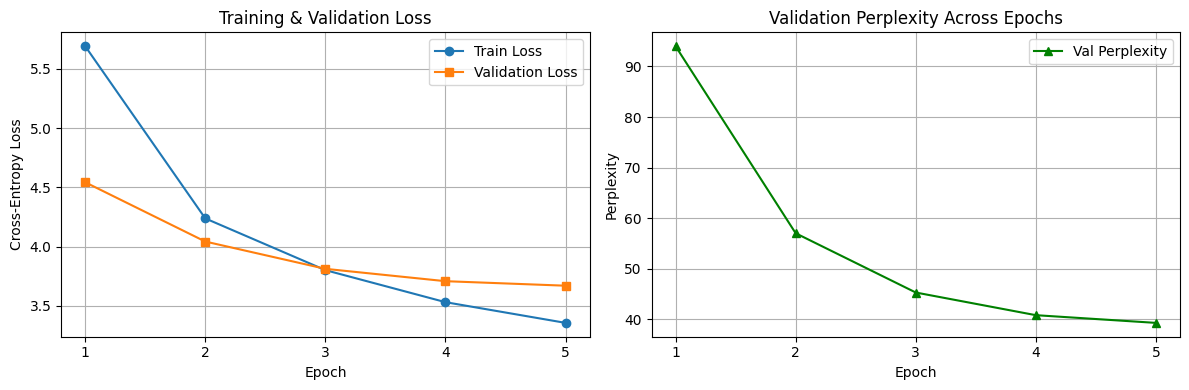

In [50]:
import math
import matplotlib.pyplot as plt

epochs = [h[0] for h in history]
train_losses = [h[1] for h in history]
val_losses = [h[2] for h in history]
val_perplexities = [math.exp(v) for v in val_losses]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Plot 1: Train vs Validation Loss
axes[0].plot(epochs, train_losses, marker="o", label="Train Loss")
axes[0].plot(epochs, val_losses, marker="s", label="Validation Loss")
axes[0].set_title("Training & Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].set_xticks(epochs)
axes[0].legend()
axes[0].grid(True)

# Plot 2: Validation Perplexity
axes[1].plot(epochs, val_perplexities, marker="^", color="green", label="Val Perplexity")
axes[1].set_title("Validation Perplexity Across Epochs")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Perplexity")
axes[1].set_xticks(epochs)
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()